In [161]:
import numpy as np
import pandas as pd


# Scarichiamo e leggiamo i dati del train.csv file
df = pd.read_csv("dati/train.csv")
df.head()

,id,Basic_Demos-Enroll_Season,Basic_Demos-Age,Basic_Demos-Sex,CGAS-Season,CGAS-CGAS_Score,Physical-Season,Physical-BMI,Physical-Height,Physical-Weight,...,PCIAT-PCIAT_18,PCIAT-PCIAT_19,PCIAT-PCIAT_20,PCIAT-PCIAT_Total,SDS-Season,SDS-SDS_Total_Raw,SDS-SDS_Total_T,PreInt_EduHx-Season,PreInt_EduHx-computerinternet_hoursday,sii
0,00008ff9,Fall,5,0,Winter,51,Fall,16.87731569,46.0,50.8,...,4,2,4,55,,,,Fall,3,2
1,000fd460,Summer,9,0,,,Fall,14.03559028,48.0,46.0,...,0,0,0,0,Fall,46,64,Summer,0,0
2,00105258,Summer,10,1,Fall,71,Fall,16.64869606,56.5,75.6,...,2,1,1,28,Fall,38,54,Summer,2,0
3,00115b9f,Winter,9,0,Fall,71,Summer,18.29234694,56.0,81.6,...,3,4,1,44,Summer,31,45,Winter,0,1
4,0016bb22,Spring,18,1,Summer,,,,,,...,,,,,,,,,,


In [162]:
print("Valori da predire:", df['sii'].unique())
print("Valori nulli nella colonna target:", df['sii'].isna().sum())
print("Tipo della classe target:", df['sii'].dtype)

Valori da predire: ['  2' '  0' '  1' '   ' '  3']
Valori nulli nella colonna target: 0
Tipo della classe target: object


In [163]:
# I dati mancanti non sono NaN, ma sono spazi ("   ")
# Sostituiamo le stringhe vuote della colonna 'sii' ("   ") con NaN
df['sii'] = df['sii'].str.strip()
df['sii'] = df['sii'].replace("", np.nan)
print("Valori nulli nella colonna target prima del drop:", df['sii'].isna().sum())

Valori nulli nella colonna target prima del drop: 1224


In [164]:
# Eliminiamuo le righe con valori NaN nella colonna 'sii'
df = df.dropna(subset=['sii'])
print("Valori nulli nella colonna target dopo il drop:", df['sii'].isna().sum())

Valori nulli nella colonna target dopo il drop: 0


In [165]:
# Convertiamo la colonna 'sii' in numerica
df['sii'] = df['sii'].astype(int)
print("Tipo della classe target:", df['sii'].dtype)

Tipo della classe target: int64


In [166]:
# Sostituiamo tutte le celle con valori mancanti ("   ") con NaN e controlliamo quanti valori mancanti ci sono
# per ciascuna colonna di interesse, in particolare consdideriamo:
# Basic_Demos-Age: età del paziente
# Basic_Demos-Sex: sesso del paziente
# PreInt_EduHx-computerinternet_hoursday: uso giornaliero di computer e internet del peziente
# Physical-BMI: indice di massa corporea del paziente
# Physical-Height: altezza del paziente (in inches)
# Physical-Weight: peso del paziente (in libbre)
# Physical-Waist_Circumference: circonferenza vita del paziente (in inches)
# SDS-SDS_Total_Raw: scala per capire i problemi legati al sonno dei pazienti
# CGAS-CGAS_Score: punteggio per capire la sanità mentale del paziente:
#                  valori alti -> buon funzionamento del cervello 
#                  valori bassi -> maggiori difficoltà

df = df.replace(r'^\s*$', np.nan, regex=True)
columnsOfInterest = ['Basic_Demos-Age ', 'BIA-BIA_BMI ', 'PreInt_EduHx-computerinternet_hoursday ', 
                    'BIA-BIA_FFMI ', 'Physical-Height ', 'Physical-Weight ', 
                    'BIA-BIA_Frame_num ', 'FGC-FGC_CU ', 'FGC-FGC_PU ',
                    'FGC-FGC_SRL_Zone ', 'FGC-FGC_SRR_Zone ', 'FGC-FGC_TL ',
                    'Physical-Systolic_BP ', 'SDS-SDS_Total_T ',
                    'PAQ_A-Season ', 'PAQ_C-Season ']


In [167]:
nan_counts = df.loc[:, columnsOfInterest].isna().sum()
nan_counts.head(10)

Basic_Demos-Age                              0
BIA-BIA_BMI                                923
PreInt_EduHx-computerinternet_hoursday      82
BIA-BIA_FFMI                               923
Physical-Height                            206
Physical-Weight                            164
BIA-BIA_Frame_num                          923
FGC-FGC_CU                                 817
FGC-FGC_PU                                 827
FGC-FGC_SRL_Zone                           859
dtype: int64

In [170]:
print("Valori da predire:", df['PAQ_A-Season '].unique())

Valori da predire: [nan 'Summer       ' 'Spring       ' 'Fall         ' 'Winter       ']


In [171]:
# Definiamo il mapping delle stagioni in numeri
season_mapping = {
    "Summer       ": 0,
    "Fall         ": 1,
    "Winter       ": 2,
    "Spring       ": 3,
    "   ": 4  # Valore nullo → assegniamo un valore diverso dagli altri
}

# Puliamo gli spazi nei nomi delle colonne


# Applichiamo la mappatura
df["PAQ_A-Season "] = df["PAQ_A-Season "].map(season_mapping).fillna(4).astype(int)
df["PAQ_C-Season "] = df["PAQ_C-Season "].map(season_mapping).fillna(4).astype(int)

# Ora puoi selezionare le colonne di interesse
dataSelected = df[columnsOfInterest]



In [172]:
# Conversione di tutte le colonne di interesse in float
dataSelected = dataSelected.astype(float)
dataSelected

,Basic_Demos-Age,BIA-BIA_BMI,PreInt_EduHx-computerinternet_hoursday,BIA-BIA_FFMI,Physical-Height,Physical-Weight,BIA-BIA_Frame_num,FGC-FGC_CU,FGC-FGC_PU,FGC-FGC_SRL_Zone,FGC-FGC_SRR_Zone,FGC-FGC_TL,Physical-Systolic_BP,SDS-SDS_Total_T,PAQ_A-Season,PAQ_C-Season
0,5.0,16.8792,3.0,13.8177,46.0,50.8,1.0,0.0,0.0,0.0,0.0,6.0,NaN,NaN,4.0,4.0
1,9.0,14.0371,0.0,12.8254,48.0,46.0,1.0,3.0,5.0,1.0,1.0,3.0,122.0,64.0,4.0,1.0
2,10.0,NaN,2.0,NaN,56.5,75.6,NaN,20.0,7.0,1.0,1.0,5.0,117.0,54.0,4.0,0.0
3,9.0,18.2943,0.0,14.0740,56.0,81.6,2.0,18.0,5.0,0.0,0.0,7.0,117.0,45.0,4.0,2.0
5,13.0,30.1865,0.0,16.6877,59.5,112.2,2.0,12.0,6.0,1.0,1.0,8.0,102.0,56.0,4.0,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3953,8.0,17.1417,2.0,13.4004,52.5,67.2,1.0,0.0,0.0,1.0,1.0,12.0,112.0,58.0,4.0,1.0
3954,7.0,13.6457,0.0,13.2315,48.5,46.6,1.0,0.0,0.0,0.0,0.0,4.5,105.0,67.0,4.0,4.0
3955,13.0,16.3642,1.0,14.0629,59.5,82.4,1.0,16.0,10.0,1.0,1.0,12.0,104.0,50.0,4.0,2.0
3957,11.0,21.4438,0.0,14.8043,60.0,109.8,2.0,15.0,0.0,1.0,1.0,14.0,116.0,77.0,4.0,2.0


In [173]:
# Sostituiamo i valori mancanti nel seguente modo:
# PreInt_EduHx-computerinternet_hoursday: media
# Physical-BMI: media
# Physical-Height: media
# Physical-Weight: media
# Physical-Waist_Circumference: media
# SDS-SDS_Total_Raw: media
# CGAS-CGAS_Score: media

for col in dataSelected.columns:
    dataSelected[col].fillna(round(dataSelected[col].mean()), inplace=True)

dataSelected.head(10)


/var/folders/zq/gk5f556s7zq33crv9lknkrhm0000gn/T/ipykernel_19578/3451047269.py:11: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  dataSelected[col].fillna(round(dataSelected[col].mean()), inplace=True)


,Basic_Demos-Age,BIA-BIA_BMI,PreInt_EduHx-computerinternet_hoursday,BIA-BIA_FFMI,Physical-Height,Physical-Weight,BIA-BIA_Frame_num,FGC-FGC_CU,FGC-FGC_PU,FGC-FGC_SRL_Zone,FGC-FGC_SRR_Zone,FGC-FGC_TL,Physical-Systolic_BP,SDS-SDS_Total_T,PAQ_A-Season,PAQ_C-Season
0,5.0,16.8792,3.0,13.8177,46.00,50.8,1.0,0.0,0.0,0.0,0.0,6.0,117.0,58.0,4.0,4.0
1,9.0,14.0371,0.0,12.8254,48.00,46.0,1.0,3.0,5.0,1.0,1.0,3.0,122.0,64.0,4.0,1.0
2,10.0,19.0000,2.0,15.0000,56.50,75.6,2.0,20.0,7.0,1.0,1.0,5.0,117.0,54.0,4.0,0.0
3,9.0,18.2943,0.0,14.0740,56.00,81.6,2.0,18.0,5.0,0.0,0.0,7.0,117.0,45.0,4.0,2.0
5,13.0,30.1865,0.0,16.6877,59.50,112.2,2.0,12.0,6.0,1.0,1.0,8.0,102.0,56.0,4.0,3.0
6,10.0,19.6629,3.0,14.7000,55.00,84.6,2.0,9.0,2.0,1.0,1.0,11.0,163.0,40.0,4.0,2.0
11,11.0,19.0000,0.0,15.0000,56.00,88.0,2.0,12.0,6.0,1.0,1.0,9.0,117.0,59.0,4.0,2.0
12,13.0,21.0814,1.0,15.6597,57.75,100.0,2.0,24.0,20.0,1.0,1.0,12.5,150.0,47.0,4.0,1.0
15,7.0,19.0000,2.0,15.0000,54.00,121.6,2.0,6.0,0.0,1.0,1.0,12.0,99.0,50.0,4.0,4.0
16,5.0,19.0000,0.0,15.0000,44.00,47.6,2.0,0.0,0.0,1.0,1.0,7.0,109.0,53.0,4.0,4.0


In [174]:
dataSelected = dataSelected.round(2)
dataSelected.head(10)

,Basic_Demos-Age,BIA-BIA_BMI,PreInt_EduHx-computerinternet_hoursday,BIA-BIA_FFMI,Physical-Height,Physical-Weight,BIA-BIA_Frame_num,FGC-FGC_CU,FGC-FGC_PU,FGC-FGC_SRL_Zone,FGC-FGC_SRR_Zone,FGC-FGC_TL,Physical-Systolic_BP,SDS-SDS_Total_T,PAQ_A-Season,PAQ_C-Season
0,5.0,16.88,3.0,13.82,46.00,50.8,1.0,0.0,0.0,0.0,0.0,6.0,117.0,58.0,4.0,4.0
1,9.0,14.04,0.0,12.83,48.00,46.0,1.0,3.0,5.0,1.0,1.0,3.0,122.0,64.0,4.0,1.0
2,10.0,19.00,2.0,15.00,56.50,75.6,2.0,20.0,7.0,1.0,1.0,5.0,117.0,54.0,4.0,0.0
3,9.0,18.29,0.0,14.07,56.00,81.6,2.0,18.0,5.0,0.0,0.0,7.0,117.0,45.0,4.0,2.0
5,13.0,30.19,0.0,16.69,59.50,112.2,2.0,12.0,6.0,1.0,1.0,8.0,102.0,56.0,4.0,3.0
6,10.0,19.66,3.0,14.70,55.00,84.6,2.0,9.0,2.0,1.0,1.0,11.0,163.0,40.0,4.0,2.0
11,11.0,19.00,0.0,15.00,56.00,88.0,2.0,12.0,6.0,1.0,1.0,9.0,117.0,59.0,4.0,2.0
12,13.0,21.08,1.0,15.66,57.75,100.0,2.0,24.0,20.0,1.0,1.0,12.5,150.0,47.0,4.0,1.0
15,7.0,19.00,2.0,15.00,54.00,121.6,2.0,6.0,0.0,1.0,1.0,12.0,99.0,50.0,4.0,4.0
16,5.0,19.00,0.0,15.00,44.00,47.6,2.0,0.0,0.0,1.0,1.0,7.0,109.0,53.0,4.0,4.0


In [175]:
columnsOfInterest = dataSelected.columns

In [176]:
# Mostra il minimo e il massimo per ogni feature
print(dataSelected[columnsOfInterest].min())
print(dataSelected[columnsOfInterest].max())

Basic_Demos-Age                             5.00
BIA-BIA_BMI                                 0.05
PreInt_EduHx-computerinternet_hoursday      0.00
BIA-BIA_FFMI                                7.86
Physical-Height                            36.00
Physical-Weight                             0.00
BIA-BIA_Frame_num                           1.00
FGC-FGC_CU                                  0.00
FGC-FGC_PU                                  0.00
FGC-FGC_SRL_Zone                            0.00
FGC-FGC_SRR_Zone                            0.00
FGC-FGC_TL                                  0.00
Physical-Systolic_BP                       49.00
SDS-SDS_Total_T                            38.00
PAQ_A-Season                                0.00
PAQ_C-Season                                0.00
dtype: float64
Basic_Demos-Age                             22.00
BIA-BIA_BMI                                 48.38
PreInt_EduHx-computerinternet_hoursday       3.00
BIA-BIA_FFMI                               217.77
P

In [177]:
# Trova le righe con peso pari a 0 -> Impossibile
zero_weight_rows = dataSelected[dataSelected['Physical-Weight '] == 0]
zero_weight_indices = zero_weight_rows.index 
print(zero_weight_indices)

df = df.drop(zero_weight_indices)
print(f"Numero di osservazioni dopo la rimozione: {df.shape[0]}")


Index([  44,  114,  202,  223,  244,  256,  504,  639,  659,  780,  796,  802,
        804, 1128, 1129, 1174, 1456, 1661, 1699, 1763, 1788, 1797, 1873, 1968,
       2010, 2051, 2096, 2218, 2301, 2459, 2533, 2557, 2582, 2600, 2627, 2711,
       2859, 2993, 3089, 3172, 3209, 3215, 3245, 3247, 3285, 3319, 3368, 3409,
       3500, 3649, 3850, 3883],
      dtype='int64')
Numero di osservazioni dopo la rimozione: 2684


In [178]:
# Rimuove le righe con peso pari a 0
dataSelected = dataSelected[dataSelected['Physical-Weight '] > 0]

print(f"Numero di osservazioni dopo la rimozione: {dataSelected.shape[0]}")


Numero di osservazioni dopo la rimozione: 2684


In [179]:
X = dataSelected
print("X shape", X.shape)

y = df.loc[:, 'sii']
print("y shape", y.shape)

X shape (2684, 16)
y shape (2684,)


In [180]:
# Contiamo quanti valori ci sono per ogni classe
# in questo modo capiamo qual è la soglia minima
# predicendo sempre la classe più frequente
y.value_counts(normalize=True)

sii
0    0.581222
1    0.267511
2    0.138599
3    0.012668
Name: proportion, dtype: float64

In [181]:
from sklearn.model_selection import train_test_split

X_train67, X_test33, y_train67, y_test33 = train_test_split(X, y, test_size=0.33, random_state=42)

X_train80, X_test20, y_train80, y_test20 = train_test_split(X, y, test_size=0.20, random_state=42)
X_train60, X_valid20, y_train60, y_valid20 = train_test_split(X_train80, y_train80, test_size=0.25, random_state=42)


In [183]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

#
# Modello usando un albero di decisione
# usando come stopping criteria il numero di foglie
# split: 67/33
#

best_leaves = None
best_train_acc = 0
best_test_acc = 0
for max_leaves in range(2,50):
    decTree = DecisionTreeClassifier(max_leaf_nodes=max_leaves)
    decTree.fit(X_train67,y_train67)

    train_acc = accuracy_score(y_true = y_train67, y_pred = decTree.predict(X_train67))
    test_acc  = accuracy_score(y_true = y_test33,  y_pred = decTree.predict(X_test33))
    
    # Salva il valore migliore
    if test_acc >= best_test_acc:
        best_train_acc = train_acc
        best_test_acc = test_acc
        best_leaves = max_leaves

print(f"Il miglior numero di foglie è {best_leaves} con una train accuracy di {best_train_acc:.3f} e con una test accuracy di {best_test_acc:.3f}")

from sklearn.model_selection import cross_val_score

decTree = DecisionTreeClassifier(max_leaf_nodes=best_leaves)

scores = cross_val_score(decTree, X_train67, y_train67, cv=20)
print("Accuracy media con cv=20:", scores.mean())

Il miglior numero di foglie è 13 con una train accuracy di 0.629 e con una test accuracy di 0.616
Accuracy media con cv=20: 0.5956554307116104


In [185]:
#
# Modello usando un albero di decisione
# usando come stopping criteria la profondità
# split: 67/33
#

bestDepth = None
best_test_acc = 0
for max_depth in range(1,20):
    decTree = DecisionTreeClassifier(max_depth=max_depth)
    decTree.fit(X_train67,y_train67)

    train_acc = accuracy_score(y_true = y_train67, y_pred = decTree.predict(X_train67))
    test_acc  = accuracy_score(y_true = y_test33,  y_pred = decTree.predict(X_test33))
    
    # Salva il valore migliore
    if test_acc > best_test_acc:
        best_test_acc = test_acc
        bestDepth = max_depth

print(f"Il miglior numero di profondità è {bestDepth} con una test accuracy di {best_test_acc:.3f}")

from sklearn.model_selection import cross_val_score

decTree = DecisionTreeClassifier(max_depth=bestDepth)

scores = cross_val_score(decTree, X_train67, y_train67, cv=20)
print("Accuracy media con cv=20:", scores.mean())


Il miglior numero di profondità è 4 con una test accuracy di 0.607
Accuracy media con cv=20: 0.5817228464419475


In [189]:
#
# Modello usando un albero di decisione con validation test
# usando come stopping criteria il numero di foglie
# split: 60/20/20
#

accuracies = []
for max_leaves in range(2,50):
    # train and predict
    dt = DecisionTreeClassifier(max_leaf_nodes=max_leaves)
    dt.fit(X_train60,y_train60)

    # compute Accuracy
    train_acc = accuracy_score(y_true = y_train60, y_pred = dt.predict(X_train60))
    valid_acc  = accuracy_score(y_true = y_valid20,  y_pred = dt.predict(X_valid20))
    
    accuracies += [ [valid_acc, max_leaves] ]

best_accuracy, best_leaves = max(accuracies)
print ( "Miglior numero di foglie:", best_leaves )

dt = DecisionTreeClassifier(max_leaf_nodes=best_leaves)
dt.fit(X_train80, y_train80)
test_acc = accuracy_score(y_true = y_test20,  y_pred = dt.predict(X_test20))
print ("Test Accuracy: {:.3f}".format(test_acc) )

from sklearn.model_selection import cross_val_score

decTree = DecisionTreeClassifier(max_leaf_nodes=best_leaves)

scores = cross_val_score(decTree, X_train80, y_train80, cv=15)
print("Accuracy media con cv=20:", scores.mean())

Miglior numero di foglie: 18
Test Accuracy: 0.588
Accuracy media con cv=20: 0.6012885262885264


In [190]:
#
# Modello usando un albero di decisione con validation test
# usando come stopping criteria la profondità
# split: 60/20/20
#

accuracies = []
for max_depth in range(1,20):
    # train and predict
    dt = DecisionTreeClassifier(max_depth=max_depth)
    dt.fit(X_train60,y_train60)

    # compute Accuracy
    train_acc = accuracy_score(y_true = y_train60, y_pred = dt.predict(X_train60))
    valid_acc  = accuracy_score(y_true = y_valid20,  y_pred = dt.predict(X_valid20))
    
    accuracies += [ [valid_acc, max_depth] ]

best_accuracy, best_depth = max(accuracies)
print ( "Miglior profondità:", best_depth )

dt = DecisionTreeClassifier(max_depth=best_depth)
dt.fit(X_train80,y_train80)
test_acc  = accuracy_score(y_true = y_test20,  y_pred = dt.predict(X_test20))
print ("Test Accuracy: {:.3f}".format(test_acc) )

from sklearn.model_selection import cross_val_score

decTree = DecisionTreeClassifier(max_depth=best_depth)

scores = cross_val_score(decTree, X_train80, y_train80, cv=15)
print("Accuracy media con cv=20:", scores.mean())

Miglior profondità: 4
Test Accuracy: 0.587
Accuracy media con cv=20: 0.5928807303807304


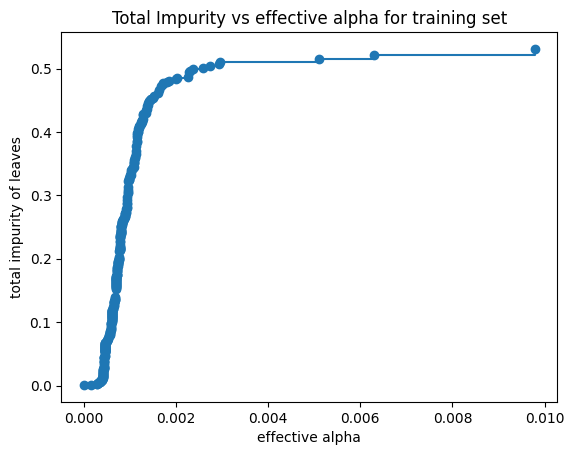

In [191]:
import matplotlib.pyplot as plt

#
# Proviamo a fare pruning usando cross-validation
# Split: 80/20
#

dt = DecisionTreeClassifier(random_state=0)
path = dt.cost_complexity_pruning_path(X_train80, y_train80)
ccp_alphas, impurities = path.ccp_alphas, path.impurities

fig, ax = plt.subplots()
ax.plot(ccp_alphas[:-1], impurities[:-1], marker="o", drawstyle="steps-post")
ax.set_xlabel("effective alpha")
ax.set_ylabel("total impurity of leaves")
ax.set_title("Total Impurity vs effective alpha for training set");

#
# Alpha vicino a 0.002 -> sembra essere un buon valore
#

In [192]:
# Costruiamo tutti gli alberi con i vari valori di ccp_alpha
ccp_alphas = ccp_alphas[:-1]
dts = []
testScores = []
for ccp_alpha in ccp_alphas:
    dt = DecisionTreeClassifier(random_state=0, ccp_alpha=ccp_alpha)
    dt.fit(X_train80, y_train80)
    dts.append(dt)

    test_acc = accuracy_score(y_true=y_test20, y_pred=dt.predict(X_test20))
    testScores.append(test_acc)

In [193]:
# Crea il modello con il valore di alpha che ha dato la migliore test accuracy
best_ccp_alpha = ccp_alphas[testScores.index(max(testScores))]
print("Best ccp_alpha:", best_ccp_alpha)

best_dt = DecisionTreeClassifier(random_state=0, ccp_alpha=best_ccp_alpha)
best_dt.fit(X_train80, y_train80)

# Calcola l'accuratezza sui dati di test
test_acc = accuracy_score(y_true=y_test20, y_pred=best_dt.predict(X_test20))
print("Test Accuracy:", test_acc)

Best ccp_alpha: 0.0013559462338880932
Test Accuracy: 0.6033519553072626


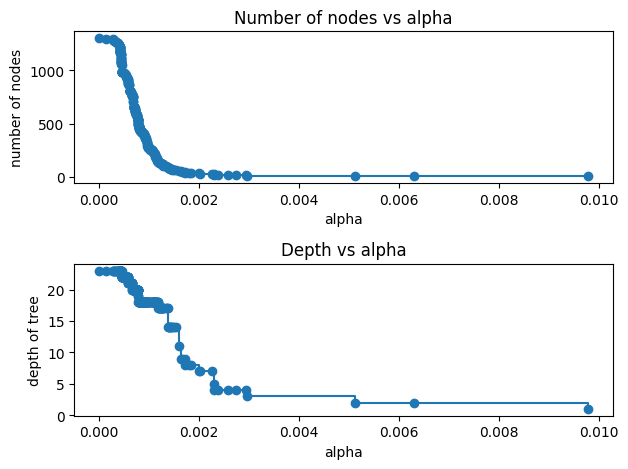

In [194]:
node_counts = [dt.tree_.node_count for dt in dts]
depth = [dt.tree_.max_depth for dt in dts]
fig, ax = plt.subplots(2, 1)
ax[0].plot(ccp_alphas, node_counts, marker="o", drawstyle="steps-post")
ax[0].set_xlabel("alpha")
ax[0].set_ylabel("number of nodes")
ax[0].set_title("Number of nodes vs alpha")
ax[1].plot(ccp_alphas, depth, marker="o", drawstyle="steps-post")
ax[1].set_xlabel("alpha")
ax[1].set_ylabel("depth of tree")
ax[1].set_title("Depth vs alpha")
fig.tight_layout()

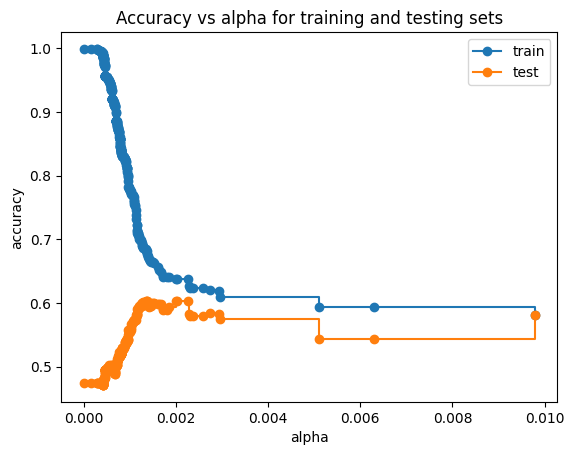

In [195]:
train_scores = [dt.score(X_train80, y_train80) for dt in dts]
# valid_scores = [dt.score(X_valid20, y_valid20) for dt in dts]
test_scores = [dt.score(X_test20, y_test20) for dt in dts]

fig, ax = plt.subplots()
ax.set_xlabel("alpha")
ax.set_ylabel("accuracy")
ax.set_title("Accuracy vs alpha for training and testing sets")
ax.plot(ccp_alphas, train_scores, marker="o", label="train", drawstyle="steps-post")
# ax.plot(ccp_alphas, valid_scores, marker="o", label="valid", drawstyle="steps-post")
ax.plot(ccp_alphas, test_scores, marker="o", label="test", drawstyle="steps-post")
ax.legend()
plt.show()

<Axes: xlabel='alpha'>

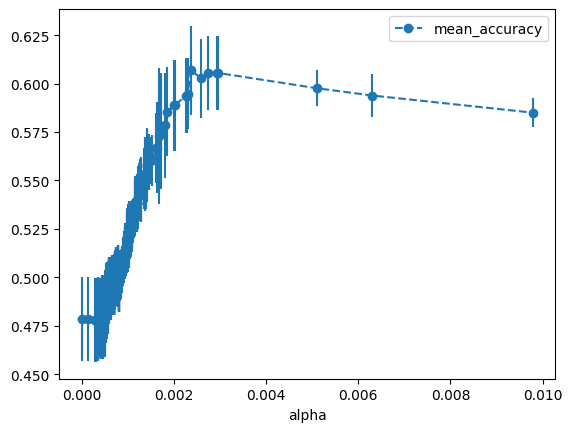

In [196]:
# Controlliamo i valori di alpha per vedere quale è più "consistente" nei dati
# vale a dire, quale valore di alpha ha la media più alta
alpha_loop_values = []
for ccp_alpha in ccp_alphas:
    dt = DecisionTreeClassifier(random_state=0, ccp_alpha=ccp_alpha)
    scores = cross_val_score(dt, X_train80, y_train80, cv=5)
    # provato anche con cv=10/15/20, ma con 5 è il risultato più alto assieme a 15
    # tuttavia, con cv=5 l'albero risulta essere più piccolo -> meglio in toeria
    alpha_loop_values.append([ccp_alpha, np.mean(scores), np.std(scores)])

alpha_results = pd.DataFrame(alpha_loop_values, columns=['alpha', 'mean_accuracy', 'std'])

alpha_results.plot(x='alpha', 
                   y='mean_accuracy', 
                   yerr='std', 
                   marker='o', 
                   linestyle='--')

In [197]:
# prendo il valore effettivo di alpha che ha la media più alta
subset = alpha_results[(alpha_results['alpha'] > 0.001) 
              & (alpha_results['alpha'] < 0.004)]

ideal_alpha = subset.loc[subset['mean_accuracy'].idxmax(), 'alpha']
ideal_alpha = float(ideal_alpha)
print("Miglior valore di alpha:", ideal_alpha)

Miglior valore di alpha: 0.002375213780580275


Test accuracy: 0.5791433891992551


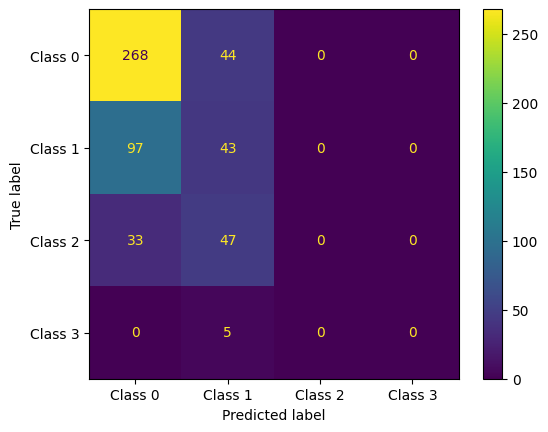

In [198]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

#
# Creo il modello con il valore di alpha ideale
# Split: 80/20
# Mostro la CM per vedere la distribuzione dei valori predetti
#

dt_pruned = DecisionTreeClassifier(random_state=42, ccp_alpha=ideal_alpha)
dt_pruned.fit(X_train80, y_train80)
print("Test accuracy:", accuracy_score(y_true=y_test20, y_pred=dt_pruned.predict(X_test20)))

# Mostra la matrice di confusione con etichette
cm = confusion_matrix(y_test20, dt_pruned.predict(X_test20))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Class 0", "Class 1", "Class 2", "Class 3"])
disp.plot()
plt.show()

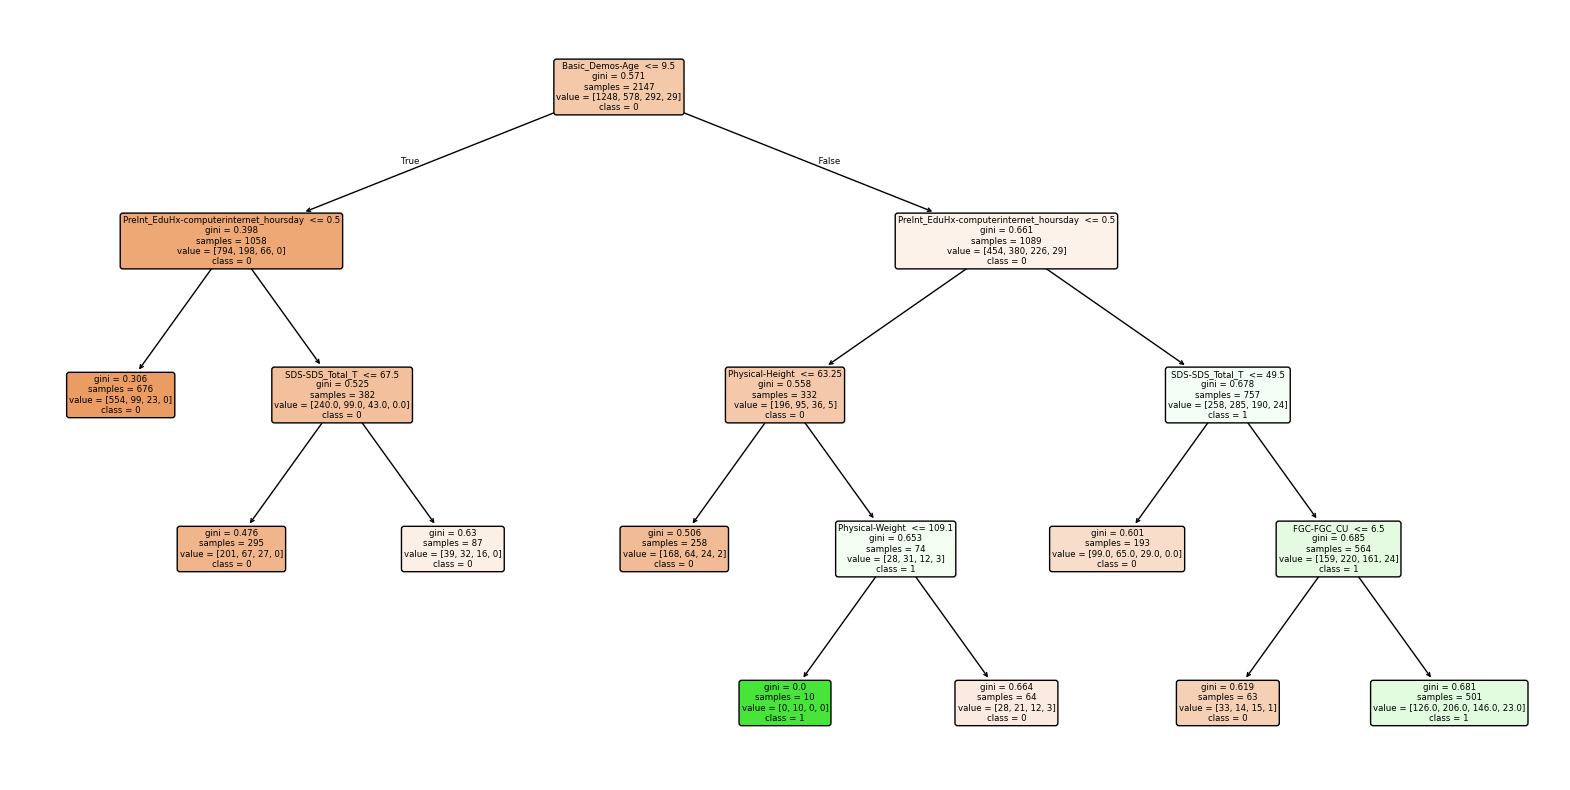

In [199]:
from sklearn.tree import plot_tree

#
# Mostro l'albero di decisione che si va' a crearea usando il valore di alpha ideale
#

plt.figure(figsize=(20,10))
plot_tree(dt_pruned, filled=True, rounded=True, feature_names=X.columns, class_names=["0", "1", "2", "3"])
plt.show()

In [200]:
from bayes_opt import BayesianOptimization

#
# Provo a fare il tuning dei parametri con Bayesian Optimization usando cross validation
# Split: 80/20
# 

def dtree_cv(max_depth, min_samples_split, min_samples_leaf, max_leaf_nodes, criteria_num, max_features_num):
    # BayesianOptimization non accetta valori categoriali
    # di devono mappare i valori numerici a stringhe
    criteria_map = {0: 'gini', 1: 'entropy', 2: 'log_loss'} # possibili stringhe accettate da 'criterion'
    max_features_map = {0: None, 1: 'sqrt', 2: 'log2'} # possibili stringhe accettate da 'max_features'

    criterion = criteria_map[(round(criteria_num))]
    max_features = max_features_map[(round(max_features_num))]

    # Definisco il modello con i parametri che si vogliono ottimizzare
    estimator = DecisionTreeClassifier(
        max_depth=int(max_depth),
        min_samples_split=int(min_samples_split),
        min_samples_leaf=int(min_samples_leaf),
        max_leaf_nodes=int(max_leaf_nodes),
        criterion=criterion,
        max_features=max_features,
        random_state=2
    )
    cval = cross_val_score(estimator, X_train80, y_train80, scoring='accuracy', cv=20)
    return cval.mean()
    # estimator.fit(X_train60, y_train60)
    # val_score = estimator.score(X_valid20, y_valid20)
    
    # return val_score

# Definisco i 'bounds' dei parametri da ottimizzare
param_bounds = {
    'max_depth': (1, 20),
    'min_samples_split': (2, 10),
    'min_samples_leaf': (1, 10),
    'max_leaf_nodes': (2, 50),
    'criteria_num': (0, 2), 
    'max_features_num': (0, 2)
}


optimizer = BayesianOptimization(
    f=dtree_cv,
    pbounds=param_bounds,
    random_state=1,
    verbose=0
)

# per n_iter piccoli il modello preferisce 'gini'
# all'aumentare di n_iter il modello preferisce 'entropy'/'log_loss
optimizer.maximize(n_iter=50, init_points=10)
best_params_bayes = optimizer.max['params']
best_params_bayes['max_depth'] = int(best_params_bayes['max_depth'])
best_params_bayes['min_samples_split'] = int(best_params_bayes['min_samples_split'])
best_params_bayes['min_samples_leaf'] = int(best_params_bayes['min_samples_leaf'])
best_params_bayes['max_leaf_nodes'] = int(best_params_bayes['max_leaf_nodes'])
best_params_bayes['criterion'] = round(best_params_bayes['criteria_num'])
best_params_bayes['max_features'] = round(best_params_bayes['max_features_num'])
best_score_bayes = optimizer.max['target']

print(f"Best Parameters (Bayesian Optimization): {best_params_bayes}")
print(f"Best Score (Bayesian Optimization): {best_score_bayes}")


Best Parameters (Bayesian Optimization): {'criteria_num': np.float64(0.834044009405148), 'max_depth': 14, 'max_features_num': np.float64(0.00022874963468977327), 'max_leaf_nodes': 16, 'min_samples_leaf': 2, 'min_samples_split': 2, 'criterion': 1, 'max_features': 0}
Best Score (Bayesian Optimization): 0.6129240221529941


In [201]:
# Creo l'albero di decisione con i parametri ottimizzati appena calcolati
dt_final = DecisionTreeClassifier(
    max_depth=int(best_params_bayes['max_depth']),
    min_samples_split=int(best_params_bayes['min_samples_split']),
    min_samples_leaf=int(best_params_bayes['min_samples_leaf']),
    max_leaf_nodes=int(best_params_bayes['max_leaf_nodes']),
    criterion='entropy',
    max_features=None,
    ccp_alpha=ideal_alpha,
    random_state=42
)
dt_final.fit(X_train80, y_train80)

cv_scores = cross_val_score(dt_final, X_train80, y_train80, cv=20, scoring='accuracy')

print(f"Valore più alto:", max(cv_scores))
print(f"Accuracy media: {cv_scores.mean()}")
print(f"Standard Deviation: {cv_scores.std()}")

train_accuracy = dt_final.score(X_train80, y_train80)
print(f"Train Accuracy: {train_accuracy:.3f}")

test_accuracy = dt_final.score(X_test20, y_test20)
print(f"Test Accuracy: {test_accuracy:.3f}")


Valore più alto: 0.6822429906542056
Accuracy media: 0.6129240221529941
Standard Deviation: 0.03025816324931356
Train Accuracy: 0.637
Test Accuracy: 0.603


0.6033519553072626


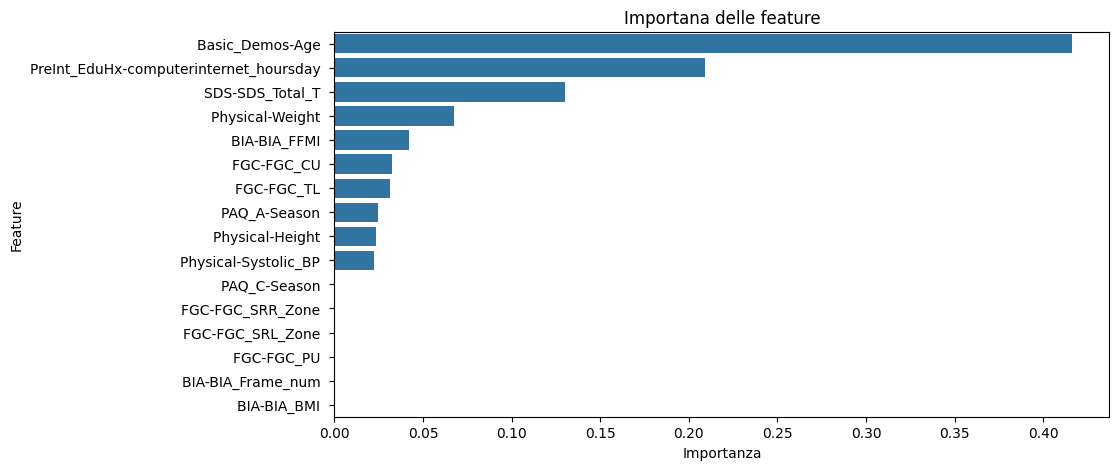

In [202]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

dt_final.fit(X_train80, y_train80)
print(accuracy_score(y_true=y_test20, y_pred=dt_final.predict(X_test20)) )

importances = dt_final.feature_importances_

feature_names = X_train80.columns
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 5))
sns.barplot(x=importances[indices], y=np.array(feature_names)[indices])
plt.xlabel("Importanza")
plt.ylabel("Feature")
plt.title("Importana delle feature")
plt.show()

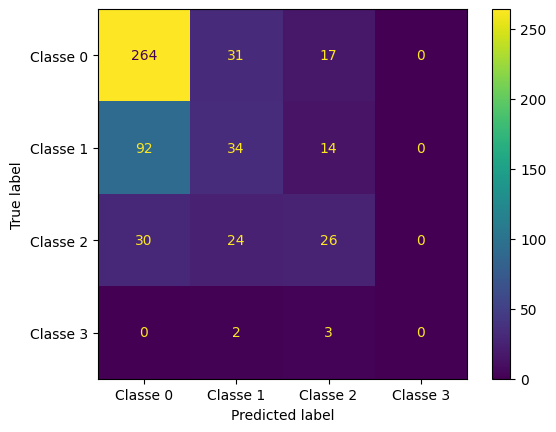

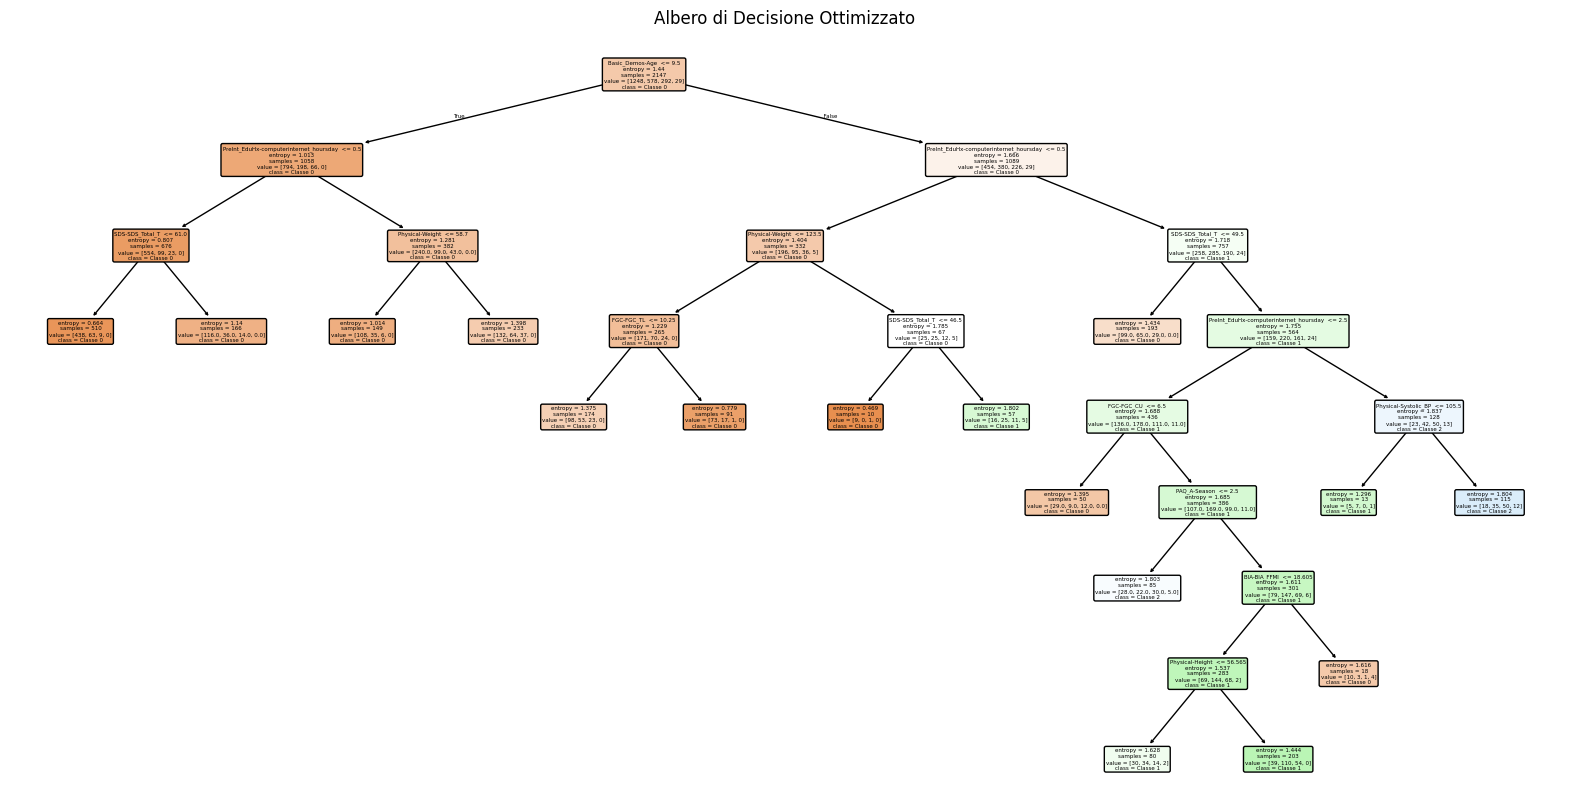

In [203]:
confMatrix = confusion_matrix(y_test20, dt_final.predict(X_test20))
disp = ConfusionMatrixDisplay(confusion_matrix=confMatrix, 
                              display_labels=["Classe 0", "Classe 1", "Classe 2", "Classe 3"])
disp.plot()
plt.show()

plt.figure(figsize=(20, 10))
plot_tree(dt_final, filled=True, feature_names=X_train80.columns, 
          class_names=['Classe 0', 'Classe 1', 'Classe 2', 'Classe 3'], rounded=True)
plt.title("Albero di Decisione Ottimizzato")
plt.show()

In [204]:
from sklearn.ensemble import BaggingClassifier

maxScore = -1
bestEstimators = -1
bestDt = None
for i in range(19, 51):
   bagged_dt = BaggingClassifier(dt_final, n_estimators=i, random_state=42)
   cv_scores = cross_val_score(bagged_dt, X_train80, y_train80, cv=5, scoring='accuracy')
   mean_cv_score = cv_scores.mean()  # Media dell'accuratezza nei fold
   
   if mean_cv_score > maxScore:
       maxScore = mean_cv_score
       bestEstimators = i
       bestDt = bagged_dt

# Una volta trovato il migliore n_estimators, allena il modello finale
bestDt.fit(X_train80, y_train80)

# Risultati
print("bestEstimators:", bestEstimators)
print("maxScore = score:", maxScore)
print("Accuracy: {:.3f}".format(accuracy_score(y_true=y_test20, y_pred=bestDt.predict(X_test20))))

bestEstimators: 23
maxScore = score: 0.6180647259717027
Accuracy: 0.596


In [210]:
from sklearn.ensemble import AdaBoostClassifier

adaboost = AdaBoostClassifier(dt_final, n_estimators=9, random_state=42)

adaboost.fit(X_train80,y_train80)
print ("Accuracy: {:.3f}".format( accuracy_score(y_true=y_test20, 
                                                 y_pred=adaboost.predict(X_test20)) ) )


Accuracy: 0.583


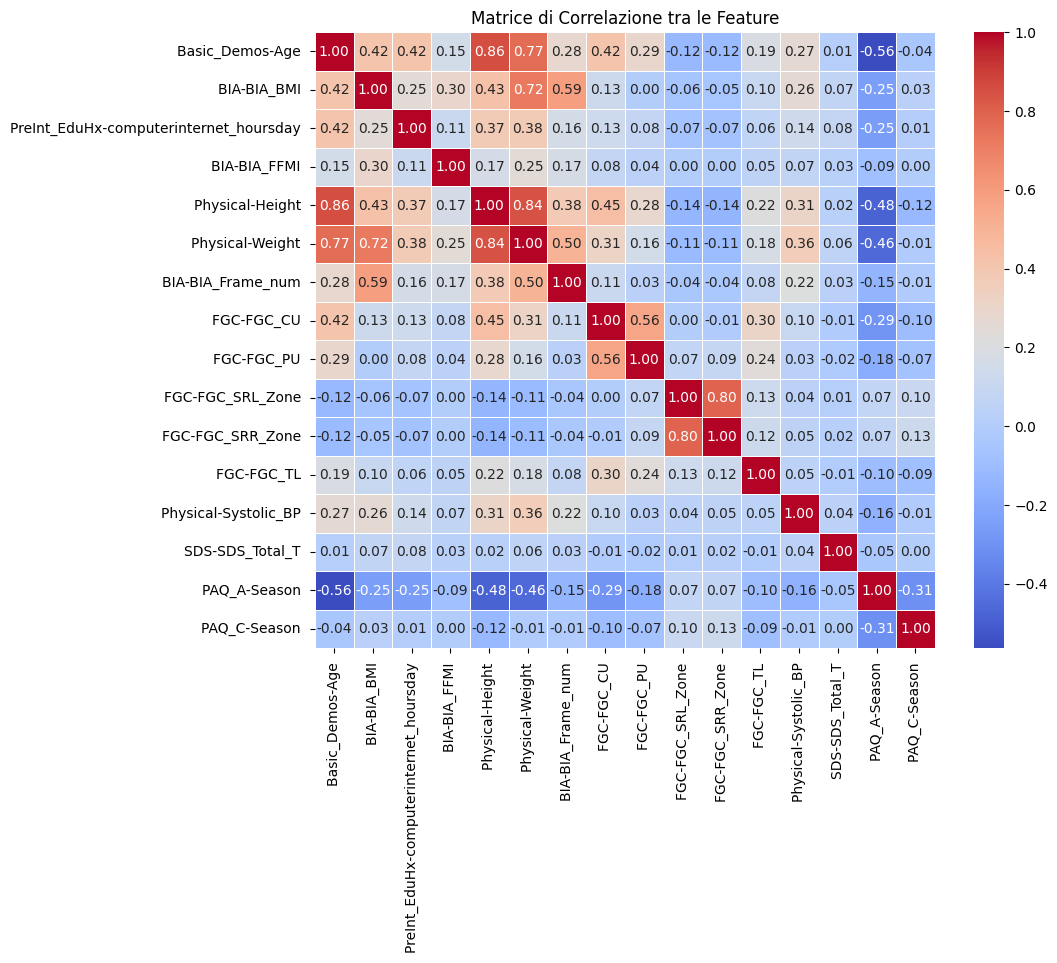

In [211]:
import seaborn as sns
import matplotlib.pyplot as plt

correlation_matrix = dataSelected[columnsOfInterest].corr()

# Crea una heatmap della matrice di correlazione
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title("Matrice di Correlazione tra le Feature")
plt.show()


Error/Bias/Variance at the last iteration: [0.65148976 0.55101024 0.10047952]


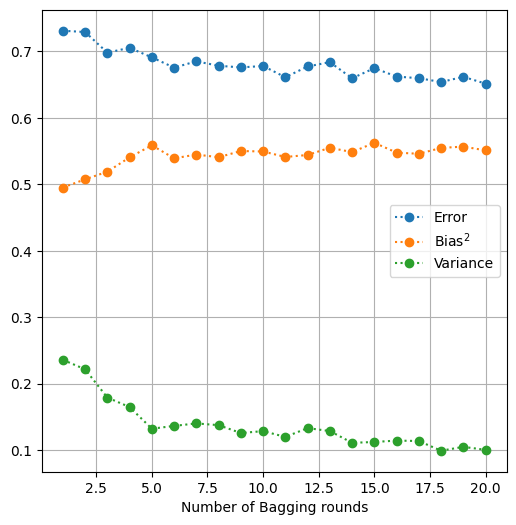

In [212]:
from sklearn.utils import resample
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier

N_TESTS = 20
stats = np.array([])
bags = range(1,21)
for l in bags:
    y_preds = np.array([])
    
    for i in range(N_TESTS):
        Xs, ys = resample(X_train80, y_train80, n_samples=int(0.67*len(y_train80)) )

        # train a decision tree classifier
        dt = DecisionTreeClassifier(
                max_depth=int(best_params_bayes['max_depth']),
                min_samples_split=int(best_params_bayes['min_samples_split']),
                min_samples_leaf=int(best_params_bayes['min_samples_leaf']),
                max_leaf_nodes=int(best_params_bayes['max_leaf_nodes']),
                criterion='gini',
                max_features=None,
                ccp_alpha=ideal_alpha,
                random_state=42
            )
        bagged_dt = BaggingClassifier(dt, n_estimators=l)
        bagged_dt.fit(Xs,ys)
        
        y_pred = bagged_dt.predict(X_test20)
        y_preds = np.column_stack( [y_preds, y_pred] ) if y_preds.size else y_pred

    dt_bias     = (y_test20-np.mean(y_preds,axis=1))**2
    dt_variance = np.var(y_preds,axis=1)
    dt_error = (y_preds - y_test20.to_numpy().reshape(-1, 1))**2

    run_stats = np.array([dt_error.mean(), dt_bias.mean(), dt_variance.mean()])
    
    stats = np.column_stack( [stats, run_stats]) if stats.size else run_stats

fig, ax = plt.subplots(figsize=(6,6))

ax.plot(bags,stats[0,:], 'o:', label='Error')
ax.plot(bags,stats[1,:], 'o:', label='Bias$^2$')
ax.plot(bags,stats[2,:], 'o:', label='Variance')
ax.set_xlabel('Number of Bagging rounds')
ax.grid()
ax.legend()

print ("Error/Bias/Variance at the last iteration:", stats[:,-1])

Error/Bias/Variance at the last iteration: [0.7707635 0.4863594 0.2844041]


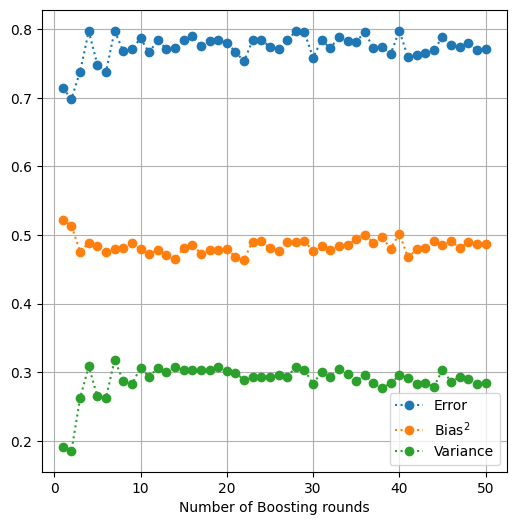

In [213]:
from sklearn.utils import resample
from sklearn.ensemble import AdaBoostClassifier

N_TESTS = 20
stats = np.array([])
boosts = range(1,51)
for l in boosts:
    y_preds = np.array([])
    
    for i in range(N_TESTS):
        Xs, ys = resample(X_train80, y_train80, n_samples=int(0.67*len(y_train80)) )

        # train a decision tree classifier
        dt = DecisionTreeClassifier(
                max_depth=int(best_params_bayes['max_depth']),
                min_samples_split=int(best_params_bayes['min_samples_split']),
                min_samples_leaf=int(best_params_bayes['min_samples_leaf']),
                max_leaf_nodes=int(best_params_bayes['max_leaf_nodes']),
                criterion='gini',
                max_features=None,
                ccp_alpha=ideal_alpha,
                random_state=42
            )
        adaboost = AdaBoostClassifier(dt, n_estimators=l)
        adaboost.fit(Xs,ys)
        
        y_pred = adaboost.predict(X_test20)
        y_preds = np.column_stack( [y_preds, y_pred] ) if y_preds.size else y_pred

    dt_bias     = (y_test20 - np.mean(y_preds, axis=1))**2
    dt_variance = np.var(y_preds, axis=1)
    dt_error    = (y_preds - y_test20.to_numpy().reshape(-1,1))**2

    run_stats = np.array([dt_error.mean(), dt_bias.mean(), dt_variance.mean()])
    
    stats = np.column_stack( [stats, run_stats]) if stats.size else run_stats
    
fig, ax = plt.subplots(figsize=(6,6))

ax.plot(boosts,stats[0,:], 'o:', label='Error')
ax.plot(boosts,stats[1,:], 'o:', label='Bias$^2$')
ax.plot(boosts,stats[2,:], 'o:', label='Variance')
ax.set_xlabel('Number of Boosting rounds')
ax.grid()
ax.legend()

print ("Error/Bias/Variance at the last iteration:", stats[:,-1])

In [214]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier

# Numero di alberi da testare
bags = range(1, 100)
stats = np.zeros((3, len(bags)))  # Per salvare errore, bias e varianza

for l_idx, l in enumerate(bags):
    # Addestriamo una Random Forest con n_estimators = l
    rf = RandomForestClassifier(
        n_estimators=l,
        max_depth=int(best_params_bayes['max_depth']),
        max_leaf_nodes=int(best_params_bayes['max_leaf_nodes']),
        criterion='gini',
        max_features=None,
        ccp_alpha=ideal_alpha,
        random_state=42,
        bootstrap=True,  # Default, ma esplicito
        n_jobs=-1, # Parallelizza per velocizzare il training
        verbose=False
    )
    
    rf.fit(X_train80, y_train80)  # Addestramento

    # Predizioni sul test set
    y_preds = np.array([tree.predict(X_test20) for tree in rf.estimators_]).T  # (n_samples, n_estimators)

    # Calcolo bias, varianza ed errore
    dt_bias = (y_test20 - np.mean(y_preds, axis=1)) ** 2
    dt_variance = np.var(y_preds, axis=1)
    dt_error = (y_preds - y_test20.to_numpy().reshape(-1, 1)) ** 2

    stats[:, l_idx] = [dt_error.mean(), dt_bias.mean(), dt_variance.mean()]  # Salva i risultati


/Users/gabrielearmani/Desktop/Università/3 anno/data_and_web_mining/progetto/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/Users/gabrielearmani/Desktop/Università/3 anno/data_and_web_mining/progetto/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/Users/gabrielearmani/Desktop/Università/3 anno/data_and_web_mining/progetto/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/Users/gabrielearmani/Desktop/Università/3 anno/data_and_web_mining/progetto/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without fea

In [221]:

maxScore = -1
bestEstimators = -1
bestDt = None
for i in range(1, 100):
   rf = RandomForestClassifier(
        n_estimators=i,
        # max_depth=int(best_params_bayes['max_depth']),
        # max_leaf_nodes=int(best_params_bayes['max_leaf_nodes']),
        # criterion='gini',
        # max_features=None,
        # ccp_alpha=ideal_alpha,
        random_state=42,
    )
   cv_scores = cross_val_score(rf, X_train80, y_train80, cv=5, scoring='accuracy')
   mean_cv_score = cv_scores.mean()  # Media dell'accuratezza nei fold
   
   if mean_cv_score > maxScore:
       maxScore = mean_cv_score
       bestEstimators = i
       bestDt = rf

# Una volta trovato il migliore n_estimators, allena il modello finale
bestDt.fit(X_train80, y_train80)

# Risultati
print("bestEstimators:", bestEstimators)
print("maxScore = score:", maxScore)
print("Accuracy: {:.3f}".format(accuracy_score(y_true=y_test20, y_pred=bestDt.predict(X_test20))))

bestEstimators: 97
maxScore = score: 0.5933832059413454
Accuracy: 0.581


In [218]:
bestDt.fit(X_train80,y_train80)
print ("Accuracy: {:.3f}".format( accuracy_score(y_true=y_test20, 
                                                 y_pred=bestDt.predict(X_test20)) ) )


Accuracy: 0.575
